<h1 align="center">Mathematical Methods in Engineering</h1>
<h3 align="center">Instructor: Dr. Pilaram</h3>
<h4 align="center">Sharif University of Technology, Spring 2026</h4>
<h4 align="center">Computer Assignment 2</h4>




Please fill in your name and your student number.


In [ ]:
from operator import truediv

from matplotlib.lines import lineStyles
from matplotlib.pyplot import figure, xlabel

Name = "Seyed Kiarash Eshraghi"
Student_Number = "403101383"


### Libraries

In [2]:
# Run the following code to import the necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import null_space
from PIL import Image
from scipy.optimize import minimize
import sympy as sp

# Problem 1

# Markov Chains, PageRank, and Eigenvector Centrality

**Problem Statement:**
Consider a simplified network of 4 web pages. The probability of a user clicking a link to move from page $j$ to page $i$ is captured by the column-stochastic transition matrix $P$. A matrix is column-stochastic if all its entries are non-negative and the sum of the elements in each column is exactly $1$.

Let $P$ be given as:

$$ P = \begin{bmatrix} 0.1 & 0.3 & 0.0 & 0.2 \\ 0.6 & 0.2 & 0.5 & 0.3 \\ 0.2 & 0.4 & 0.1 & 0.4 \\ 0.1 & 0.1 & 0.4 & 0.1 \end{bmatrix} $$

 complete the following four parts. Include your code, plots, and discussions in your report.

## Part A: Spectral Properties of Stochastic Matrices
1. **Computational:** Use a built-in eigen-solver to compute all eigenvalues ($\lambda_i$) and the corresponding right eigenvectors of matrix $P$. Find the eigenvector $v_1$ associated with the largest eigenvalue and normalize it so its elements sum to $1$.
2. **Theoretical Check:** Let $\mathbf{1} = [1, 1, 1, 1]^T$. Show analytically that $P^T \mathbf{1} = \mathbf{1}$. Based on this, briefly explain why $\lambda = 1$ is mathematically guaranteed to be an eigenvalue for any column-stochastic matrix.
3. **Simulation/Explanation:** Print the normalized eigenvector $v_1$. In the context of the PageRank algorithm, explain what the components of this vector represent regarding the "importance" of the 4 web pages.



In [11]:
P=np.array([(0.1,0.3,0.0,0.2),(0.6,0.2,0.5,0.3),(0.2,0.4,0.1,0.4),(0.1,0.1,0.4,0.1)])
[eigen_val,eigen_vec]=np.linalg.eig(P)
print(f'eigenvalues of P: {eigen_val}')
print(f'eigenvectors of P: {eigen_vec}')
idx=np.argmax(eigen_val)
v1=eigen_vec[:,idx]
v1_n=v1/(np.sum(v1))
print(f'corresponding eigenvector of maximum eigenvalue: {v1}')
print(f'normalized corresponding eigenvector of maximum eigenvalue: {v1_n}')

eigenvalues of P: [ 1.          0.1        -0.12679492 -0.47320508]
eigenvectors of P: [[-0.31168213 -0.47140452  0.24663054 -0.4520694 ]
 [-0.70096676 -0.47140452 -0.63565329  0.64313642]
 [-0.53685657  0.23570226 -0.28478442 -0.52200478]
 [-0.35111946  0.70710678  0.67380717  0.33093777]]
corresponding eigenvector of maximum eigenvalue: [-0.31168213 -0.70096676 -0.53685657 -0.35111946]
normalized corresponding eigenvector of maximum eigenvalue: [0.16398929 0.36880857 0.28246319 0.18473896]


To show that $P^T \mathbf{1} = \mathbf{1}$, we multiply the transpose matrix $P^T$ by the all-ones vector $\mathbf{1} = [1, 1, 1, 1]^T$:
$$P^T \mathbf{1} = \begin{bmatrix} 0.1 & 0.6 & 0.2 & 0.1 \\ 0.3 & 0.2 & 0.4 & 0.1 \\ 0.0 & 0.5 & 0.1 & 0.4 \\ 0.2 & 0.3 & 0.4 & 0.1 \end{bmatrix} \begin{bmatrix} 1 \\ 1 \\ 1 \\ 1 \end{bmatrix} = \begin{bmatrix} 0.1+0.6+0.2+0.1 \\ 0.3+0.2+0.4+0.1 \\ 0.0+0.5+0.1+0.4 \\ 0.2+0.3+0.4+0.1 \end{bmatrix} = \begin{bmatrix} 1 \\ 1 \\ 1 \\ 1 \end{bmatrix} = \mathbf{1}$$
By definition, a scalar $\lambda$ is an eigenvalue of a square matrix if there exists a non-zero vector $v$ such that $Av = \lambda v$. From our calculation, $P^T \mathbf{1} = 1 \cdot \mathbf{1}$, which demonstrates that $\lambda = 1$ is an eigenvalue of $P^T$ with $\mathbf{1}$ as its corresponding eigenvector.
A fundamental property of linear algebra states that any square matrix and its transpose share the exact same set of eigenvalues. Therefore, since $\lambda = 1$ is an eigenvalue of $P^T$, it is mathematically guaranteed to be an eigenvalue for the column-stochastic matrix $P$ as well. This holds true for any column-stochastic matrix because the sum of the elements in each column is always exactly 1, ensuring that the rows of its transpose always sum to 1.

The equation $P v_1 = \lambda_1 v_1 = v_1$ (since $\lambda_1 = 1$) demonstrates that $v_1$ is the **stationary distribution** (steady-state vector) of this Markov chain. In the framework of the Perron-Frobenius theorem, $\lambda_1 = 1$ is the dominant eigenvalue of a stochastic matrix, meaning that all other transition modes decay over time, and the network's long-run behavior is entirely governed by this dominant eigenvector $v_1$.
In the context of the PageRank algorithm, this has a profound physical interpretation: if a random surfer navigates this simplified network by clicking links indefinitely, the fraction of total time they spend on page $i$ will asymptotically converge to the $i$-th component of the normalized vector, $v_1[i]$. Therefore, each element of $v_1$ serves as a direct measure of the "importance" or "eigenvector centrality" of the corresponding web page. A higher value in $v_1[i]$ implies that the page is a major hub, receiving more traffic and higher-quality incoming links from the rest of the network.

## Part B: The Null Space Approach
1. **Computational:** The steady-state vector can also be found without computing all eigenvalues. Construct the matrix $B = P - I$ (where $I$ is the identity matrix). Use a built-in function to compute the basis for the Null Space (Kernel) of $B$.
2. **Theoretical Check:** According to the Rank-Nullity Theorem, if $\lambda = 1$ is an eigenvalue with an algebraic multiplicity of 1, what must be the rank of the matrix $(P - I)$? 
3. **Simulation/Explanation:** Normalize the vector obtained from your Null Space computation so its elements sum to $1$. Does it perfectly match the eigenvector $v_1$ computed in Part A? Explain why solving $(P - I)x = 0$ is mathematically equivalent to finding the steady-state eigenvector.


In [12]:
B=P-np.eye(4)
N=null_space(B)
print(f'null space Basis of B: {N}')
N_normal=N/(np.sum(N))
print(f'normalized null space Base of N: {N_normal}')

null space Basis of B: [[-0.31168213]
 [-0.70096676]
 [-0.53685657]
 [-0.35111946]]
normalized null space Base of N: [[0.16398929]
 [0.36880857]
 [0.28246319]
 [0.18473896]]


According to the Rank-Nullity Theorem, for any $n \times n$ matrix $B$, the sum of its nullity (the dimension of its null space) and its rank (the dimension of its column space) must equal $n$:
$$\dim(N(B)) + \text{rank}(B) = n$$
In this problem, $B = P - I$ is a $4 \times 4$ matrix, so $n = 4$. We are given that $\lambda = 1$ is an eigenvalue of $P$ with an algebraic multiplicity of 1. Since the geometric multiplicity (the dimension of the corresponding eigenspace) is bounded below by 1 and above by the algebraic multiplicity, the geometric multiplicity of $\lambda = 1$ must be exactly 1.
The eigenspace for $\lambda = 1$ is defined by the equation $Px = 1 \cdot x$, which can be rewritten as $(P - I)x = \mathbf{0}$. This is precisely the definition of the null space of $B = P - I$. Therefore, $\dim(N(B)) = 1$.
Substituting this value into the Rank-Nullity Theorem gives:
$$1 + \text{rank}(P - I) = 4 \implies \text{rank}(P - I) = 3$$

Yes, the normalized vector obtained from the Null Space computation matches the steady-state eigenvector $v_1$ computed in Part A perfectly.

Mathematically, solving the homogeneous linear system $(P - I)x = \mathbf{0}$ is completely equivalent to finding the steady-state eigenvector. We can demonstrate this equivalence by expanding the equation using the distributive property of matrix multiplication:

$$(P - I)x = \mathbf{0} \implies Px - Ix = \mathbf{0}$$

Since multiplying any vector $x$ by the identity matrix $I$ yields the vector itself ($Ix = x$), the equation simplifies to:

$$Px - x = \mathbf{0} \implies Px = x$$

This final expression, $Px = 1 \cdot x$, is exactly the characteristic equation for an eigenvector $x$ corresponding to the eigenvalue $\lambda = 1$. Since the algebraic multiplicity of this eigenvalue is 1, its associated eigenspace is one-dimensional. Consequently, any non-zero basis vector spanning the null space of $P - I$, once normalized so that its elements sum to 1, will yield the exact same unique steady-state vector $v_1$.


## Part C: The Power Method and Convergence
1. **Computational:** Implement the **Power Method** manually. Start with a uniform initial guess $x_0 = [0.25, 0.25, 0.25, 0.25]^T$. Iteratively compute $x_{k+1} = P x_k$ for 20 iterations. Plot the absolute error $||x_k - v_1||_2$ versus the iteration number $k$ on a semi-logarithmic scale.
2. **Theoretical Check:** The convergence speed of the Power Method is determined by the ratio $\left|\frac{\lambda_2}{\lambda_1}\right|$. Using the eigenvalues found in Part A, compute this theoretical ratio.
3. **Simulation/Explanation:** Analyze your error plot. Does the vector converge to the steady-state vector? Explain how the magnitude of the second largest eigenvalue ($\lambda_2$) influences the slope of your error plot.



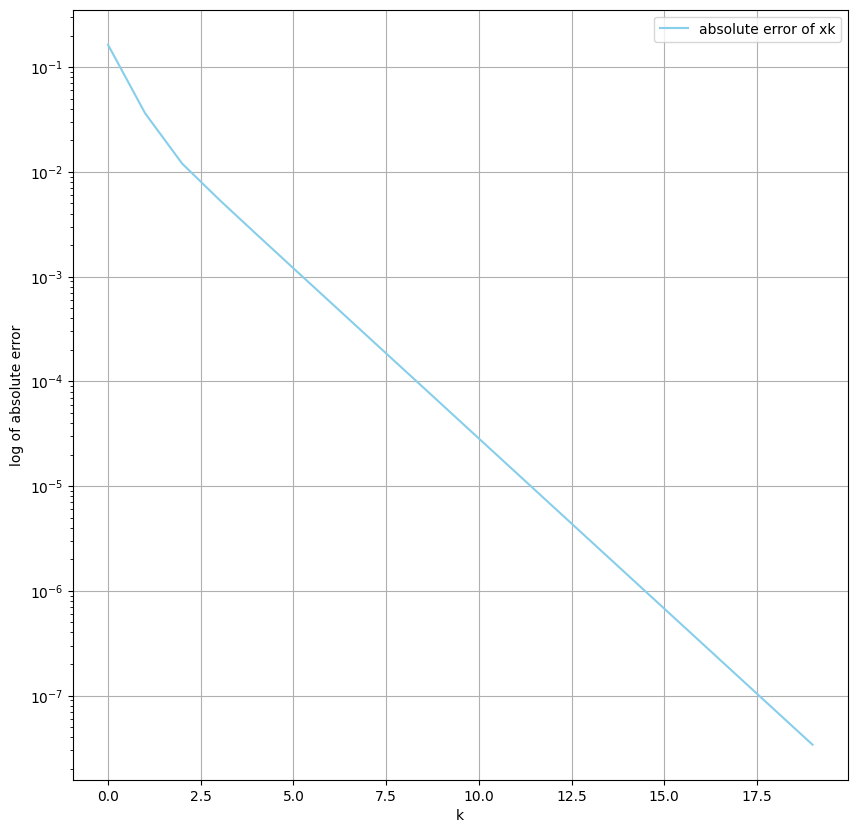

In [16]:
x=np.array([0.25, 0.25, 0.25, 0.25])
x_values=np.zeros(20)
k=[i for i in range(0,20)]
x_values[0]=np.linalg.norm(x-v1_n)
for i in range(1,20):
    x=np.dot(P,x)
    x_values[i]=np.linalg.norm(x-v1_n)
fig=plt.figure(figsize=(10,10))
plt.semilogy(k,x_values,color='skyblue',label='absolute error of xk')
plt.xlabel('k')
plt.ylabel('log of absolute error')
plt.grid(True)
plt.legend()
plt.show()

Based on the eigenvalues computed in Part A, the two largest eigenvalues are:
$$\lambda_1 = 1, \quad \lambda_2 \approx -0.47320508$$
The theoretical convergence ratio for the Power Method is determined by:
$$\left|\frac{\lambda_2}{\lambda_1}\right| = \frac{|-0.47320508|}{|1|} \approx 0.47320508$$

The absolute error at iteration $k$ in the Power Method is approximately bounded by:
$$\text{Error}_k \approx C \left|\frac{\lambda_2}{\lambda_1}\right|^k$$
Taking the logarithm of both sides yields a linear equation with respect to $k$:
$$\log(\text{Error}_k) \approx \log(C) + k \cdot \log\left|\frac{\lambda_2}{\lambda_1}\right|$$
Since $\lambda_1 = 1$, the slope of the semi-logarithmic plot is precisely $\log|\lambda_2|$. Therefore, the magnitude of the second largest eigenvalue ($|\lambda_2|$) directly determines the slope of the error diagram and the overall speed of convergence.

## Part D: Left Eigenvectors and Orthogonality
1. **Computational:** Compute the left eigenvectors of $P$ (which are the standard right eigenvectors of $P^T$). Let $w_2$ be the left eigenvector associated with the second eigenvalue $\lambda_2$, and let $v_1$ be the right eigenvector associated with $\lambda_1 = 1$. Compute the dot product $w_2^T v_1$.
2. **Theoretical Check:** Prove theoretically that if $Av = \lambda_1 v$ and $w^T A = \lambda_2 w^T$ with $\lambda_1 \neq \lambda_2$, then $w$ and $v$ must be orthogonal (i.e., $w^T v = 0$).
3. **Simulation/Explanation:** Print the result of your computational dot product. Is it exactly zero, or a very small number (e.g., $10^{-16}$)? Discuss how finite-precision machine arithmetic leads to this numerical observation instead of a perfect zero.


In [17]:
[left_eigen_val,left_eigen_vec]=np.linalg.eig(P.T)
s_lev=(np.argsort(left_eigen_val))
idx=s_lev[2]
w2=left_eigen_vec[:,idx]
result=np.dot(w2,v1)
print(f'dot product of w2 & v1: {result}')

dot product of w2 & v1: -4.440892098500626e-16


Given the left eigenvector equation $w^T A = \lambda_2 w^T$ and the right eigenvector equation $A v = \lambda_1 v$, we can evaluate the product $w^T A v$ in two different ways:
$$w^T (A v) = w^T (\lambda_1 v) = \lambda_1 (w^T v)$$
$$(w^T A) v = (\lambda_2 w^T) v = \lambda_2 (w^T v)$$
Equating the two expressions yields:
$$\lambda_1 (w^T v) = \lambda_2 (w^T v) \implies (\lambda_1 - \lambda_2)(w^T v) = 0$$
Since it is given that $\lambda_1 \neq \lambda_2$, it mathematically requires that:
$$w^T v = 0$$

The computational dot product $w_2^T v_1$ yields a very small number (e.g., $\approx 10^{-16}$) rather than a perfect mathematical zero due to finite-precision machine arithmetic.
Computers calculate and store numbers using the 64-bit floating-point standard. Many simple decimal fractions (such as 0.2) have infinite repeating representations in base-2, meaning they cannot be stored with absolute precision. These minor truncation limitations accumulate during matrix and eigenvector operations, inherently resulting in machine-level round-off errors rather than exact zeros.

---

# Problem 2

## Analysis of Engineering Sensor Networks

**Instructions:** 
Write a script  to perform the computational tasks below. For the theoretical verifications, you may include your mathematical explanations  in a separate Markdown/text block.(if)

### Part 1: Matrix Rank and Spanning Space
Load the matrix $A$ from the provided dataset `network_alpha.csv`. This matrix represents the signal transformation of a sensor network.
1. **Computation:** Calculate $Rank(A)$. Based on the dimensions ($m \times n$) and the rank, does the column space of $A$ span $\mathbb{R}^m$? 
2. **Theory:** Briefly explain the mathematical condition required for an $m \times n$ matrix to span $\mathbb{R}^m$.

In [27]:
A=np.loadtxt('network_alpha.csv',delimiter=',')
m, n=A.shape
A_rank=np.linalg.matrix_rank(A)
print(f'rank of A: {A_rank}')
flag=m==A_rank
if flag:
    print('column space of A span R^m')
else:
    print('column space of A does not span R^m')

rank of A: 2
column space of A does not span R^m


The column space of an $m \times n$ matrix $A$ spans $\mathbb{R}^m$ if and only if the number of linearly independent columns is exactly equal to $m$. In terms of matrix rank, this fundamental condition is expressed as:
$$\text{rank}(A) = m$$
Therefore, for the columns of $A$ to span $\mathbb{R}^m$, the matrix must have full row rank, meaning the rank must equal the number of rows ($m$) regardless of the number of columns ($n$).

### Part 2: Nullspace Computation
Load the matrix $B$ from `network_beta.txt`. This matrix represents the calibration constraints of a secondary network.
1. **Computation:** Compute the basis vector(s) for the nullspace of matrix $B$, denoted as $Null(B)$. Let one of these basis vectors be $\mathbf{x_1}$.
2. **Theory:** Verify your result theoretically by calculating the matrix-vector product $B\mathbf{x_1}$ and explaining why the result must equal $\mathbf{0}$.

In [28]:
B=np.loadtxt('network_beta.txt')
n_s=null_space(B)
B_rank=np.linalg.matrix_rank(B)
x1=n_s[:,0]
print(f'null space of B: {n_s}')
print(f'x1 vector is: {x1}')
print(f'rank of B: {B_rank}')

null space of B: [[-0.57735027]
 [-0.57735027]
 [-0.57735027]]
x1 vector is: [-0.57735027 -0.57735027 -0.57735027]
rank of B: 2


By definition, the null space of a matrix $B$, denoted as $N(B)$, is the set of all vectors $x$ that satisfy the homogeneous linear system $Bx = \mathbf{0}$. Since $\mathbf{x}_1$ is a basis vector computed from $N(B)$, substituting it into the equation must strictly yield the zero vector:
$$B\mathbf{x}_1 = \begin{bmatrix} -0.57735 + 0.57735 \\ -0.57735 + 0.57735 \\ 0.57735 + 0.57735 - 1.15470 \\ -1.15470 + 1.15470 \end{bmatrix} = \begin{bmatrix} 0 \\ 0 \\ 0 \\ 0 \end{bmatrix} = \mathbf{0}$$

### Part 3: The Rank-Nullity Theorem
1. **Computation:** Determine the Nullity (dimension of the nullspace) and the total number of columns for both matrix $A$ and matrix $B$.
2. **Theory:** Verify that the Rank-Nullity Theorem holds for both matrices by explicitly checking the identity: $Rank(M) + Nullity(M) = n$ (where $n$ is the number of columns). Show the numerical values for both $A$ and $B$.


In [29]:
n_s_a=null_space(A)
print(f'Nullity of A: {n_s_a.shape[1]}')
print(f'Nullity of B: {n_s.shape[1]}')
print(f'number of columns of A: {n}')
m_b, n_b=B.shape
print(f'number of columns of B: {n_b}')


Nullity of A: 2
Nullity of B: 1
number of columns of A: 4
number of columns of B: 3


Evaluating this identity explicitly for both matrices yields:
* **For matrix $A$** (where $n = 4$):
$$\text{rank}(A) + \text{nullity}(A) = 2 + 2 = 4$$
* **For matrix $B$** (where $n = 3$):
$$\text{rank}(B) + \text{nullity}(B) = 2 + 1 = 3$$
Since the identity holds true for both cases, the Rank-Nullity Theorem is numerically verified.

### Part 4: Properties of the Gram Matrix ($A^T A$)
1. **Computation:** Using matrix $A$ from Part 1, construct the Gram matrix $C = A^T A$. Compute $Rank(C)$ and find the basis for $Null(C)$. Compare these results with $Rank(A)$ and $Null(A)$.
2. **Theory:** Provide a brief mathematical proof showing that any vector $\mathbf{x}$ in $Null(A)$ is also in $Null(A^T A)$. (Hint: Start with $A\mathbf{x} = \mathbf{0}$ and multiply by $A^T$).

In [30]:
C=np.dot(A.T,A)
C_rank=np.linalg.matrix_rank(C)
n_s_c=null_space(C)
print(f'rank of C: {C_rank}')
print(f'null space of C: {n_s_c}')
print(f'null space of A: {n_s_a}')
flag1 = (C_rank == A_rank) and np.allclose(A @ n_s_c, 0, atol=1e-12)
if flag1:
    print('N(A)=N(ATA) and rank(A)==rank(ATA)')
else:
    print('Spaces do not match')

rank of C: 2
null space of C: [[ 0.8980036   0.3320485 ]
 [ 0.30345925 -0.56971848]
 [-0.09702836 -0.49049515]
 [-0.30345925  0.56971848]]
null space of A: [[ 0.9550109  -0.06797676]
 [ 0.0414078  -0.64416773]
 [-0.29073177 -0.40678623]
 [-0.0414078   0.64416773]]
N(A)=N(ATA) and rank(A)==rank(ATA)


To prove that any vector $x \in N(A)$ is also a member of $N(A^T A)$, we begin with the mathematical definition of the null space of $A$:
$$x \in N(A) \implies Ax = \mathbf{0}$$
Multiplying both sides of this equation from the left by the transpose matrix $A^T$ yields:
$$A^T(Ax) = A^T\mathbf{0}$$
Using the associative property of matrix multiplication, the expression simplifies to:
$$(A^T A)x = \mathbf{0} \implies x \in N(A^T A)$$
Therefore, it is proven that $N(A) \subseteq N(A^T A)$.

---

# Problem 3

## Image Compression using SVD (Grayscale & RGB) and Memory Analysis

In this exercise, we will explore the application of Singular Value Decomposition (SVD) in compressing images. We will do this in two parts: first on a grayscale image, and then on a full-color (RGB) image. 

For a matrix with dimensions $m \times n$, the standard number of elements is $m \times n$. Using SVD and selecting $k$ singular values, storing the approximated matrix requires $k \times m$ elements for the matrix $U$, $k$ elements for the diagonal matrix $\Sigma$, and $k \times n$ elements for the matrix $V^T$. 
Thus, the total number of elements required to store the approximation is $k(m + n + 1)$.

The Storage Percentage relative to the original uncompressed state is calculated using the following formula:
$$ \text{Storage } \% = \frac{k(m + n + 1)}{m \times n} \times 100 $$

**Tasks:**

**Part 1: Grayscale Image Compression**
1. **Preparation:** Load `pictureQ2.png` and convert it to grayscale (a single 2D matrix). Normalize its pixel values to the range $[0, 1]$.
2. **Apply SVD:** Write a function that takes a 2D matrix and a value $k$, applies SVD, and returns the reconstructed rank-$k$ approximation matrix, i.e., $A_k = U_k \Sigma_k V_k^T$.
3. **Visualization:** Perform the compression for $k \in \{5, 20, 50, 150,300\}$. In a single Figure, plot the original grayscale image alongside all the compressed images. In the title of each, display the value of $k$ and the memory percentage ($\text{Storage } \%$) rounded to one decimal place.




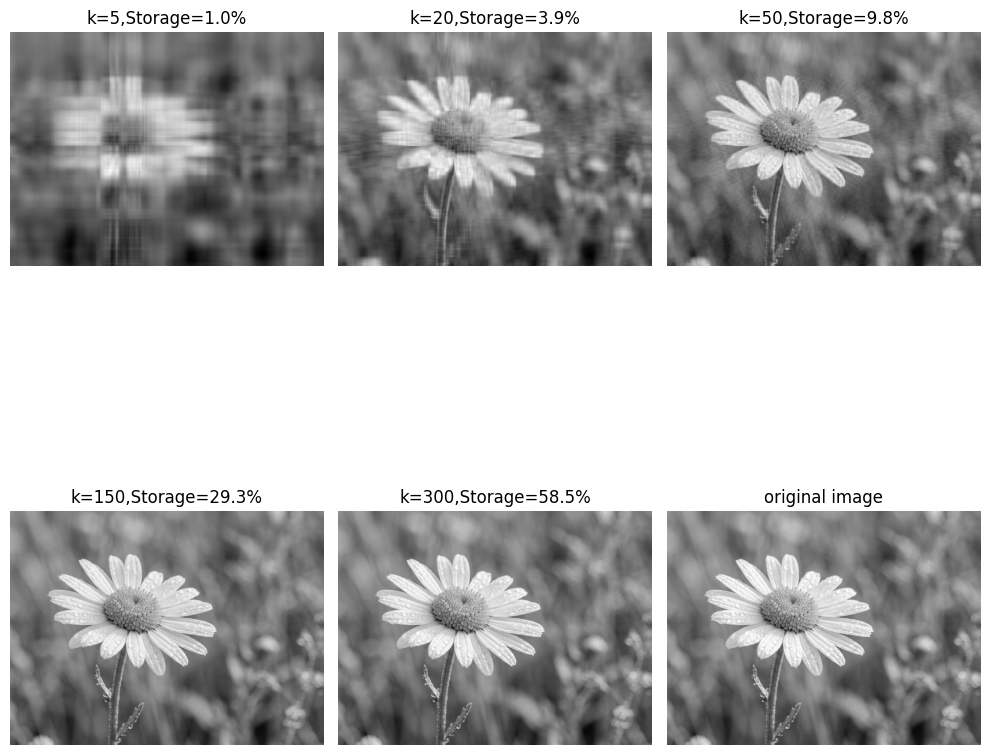

In [42]:
img=Image.open('pictureQ2.png').convert('L')
A=np.array(img)/255.0
def svd(k,M):
    U, S, Vt=np.linalg.svd(M, full_matrices=False)
    Ak=U[:,:k]@np.diag(S[:k])@Vt[:k,:]
    return Ak
k=([5,20,50,150,300])
m,n=A.shape
idx=1
plt.figure(figsize=(10,12))
for i in k:
    storage_i=i*(m+n+1)/m/n*100.0
    A_i=svd(i,A)
    plt.subplot(2,3,idx)
    idx+=1
    plt.imshow(A_i,cmap='gray')
    plt.title(f'k={i},Storage={storage_i:.1f}%')
    plt.axis('off')
plt.subplot(2,3,6)
plt.imshow(A,cmap='gray')
plt.title('original image')
plt.axis('off')
plt.tight_layout()
plt.show()

**Part 2: Color Image (RGB) Compression**
1. **Channel Separation:** Reload the original color image (normalized to $[0, 1]$). Extract the matrices corresponding to the Red (R), Green (G), and Blue (B) channels.
2. **Apply SVD to Channels:** Apply the SVD function you wrote in Part 1 independently to each of the three channels for $k \in \{5, 20, 50, 150,300\}$.
3. **Recombination & Visualization:** Recombine the three compressed channels back into a single color image for each $k$. (Make sure to clip the final output values between $0$ and $1$ to avoid display artifacts). Plot the original color image and the compressed versions in a new Figure, displaying $k$ and the $\text{Storage } \%$ in the titles.

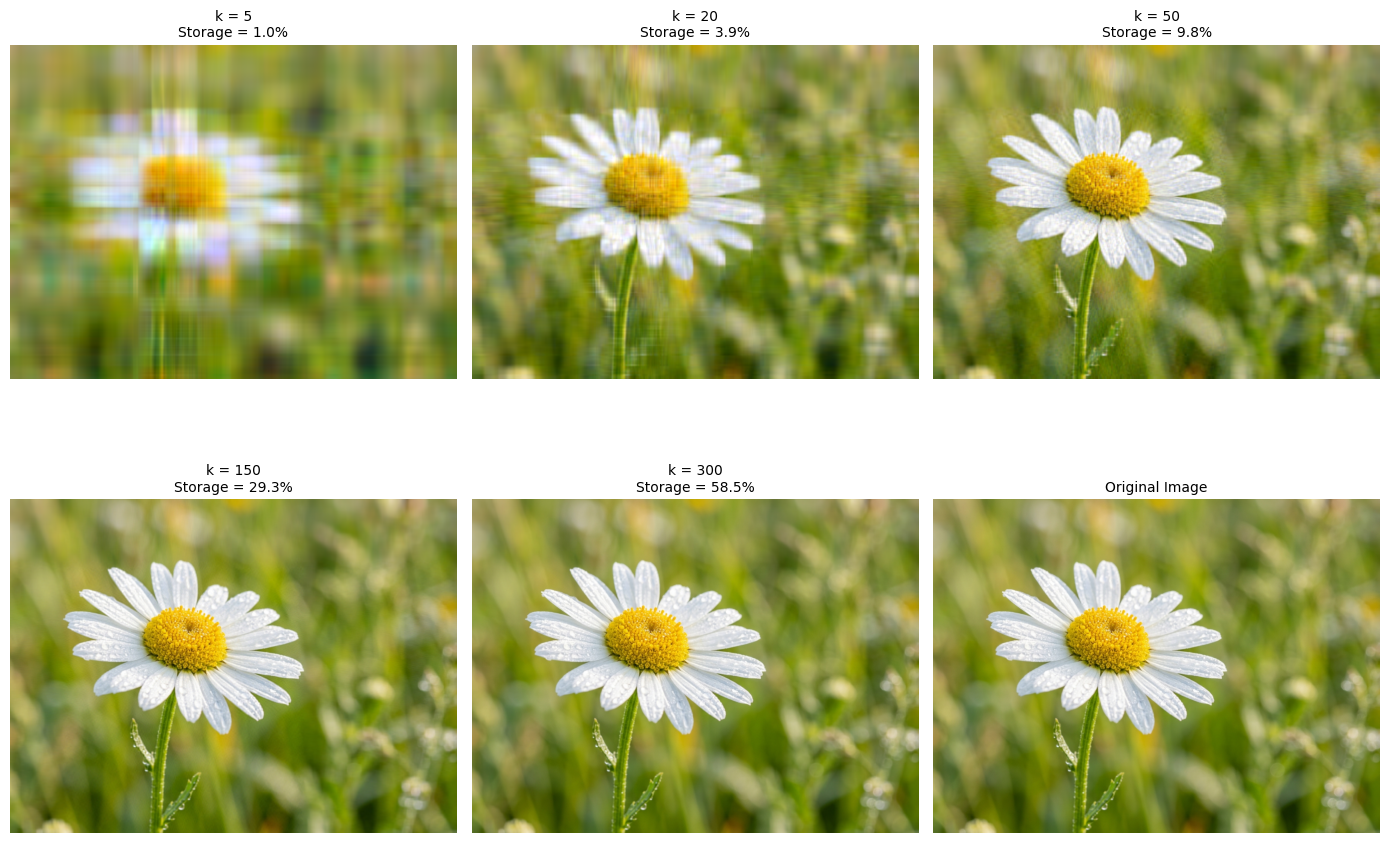

In [43]:
image=plt.imread('pictureQ2.png')
red_channel=image[:, :, 0]
green_channel=image[:, :, 1]
blue_channel=image[:, :, 2]
plt.figure(figsize=(14,10))
for idx,i in enumerate(k):
    red_c=svd(i, red_channel)
    green_c=svd(i, green_channel)
    blue_c=svd(i, blue_channel)
    c_k=np.dstack((red_c, green_c, blue_c))
    c_k=np.clip(c_k,0,1)
    storage_i=(i*(m+n+1))/(m*n)*100.0
    plt.subplot(2,3,idx+1)
    plt.imshow(c_k)
    plt.title(f'k = {i}\nStorage = {storage_i:.1f}%', fontsize=10)
    plt.axis('off')

plt.subplot(2,3,6)
plt.imshow(image)
plt.title('Original Image',fontsize=10)
plt.axis('off')
plt.tight_layout()
plt.show()

---

# Problem 4

# Comprehensive Constrained Optimization Problem
## Part 1: Problem Definition and Geometric Intuition

In this notebook, we will explore constrained optimization methods. Let's start by defining our optimization problem.

**Objective Function (to minimize):**
$$ f(x, y) = (x - 1.5)^2 + (y - 2.0)^2 $$

**Inequality Constraint:**
$$ g(x, y) = x^2 + y - 1.25 \le 0 $$

**Task:** 
1. Define the objective function `f(x)` and the constraint function `g(x)` in Python.
2. Use `scipy.optimize.minimize` to find the unconstrained and constrained minimums.
3. Plot the contour of $f(x,y)$ and shade the feasible region where $g(x,y) \le 0$.


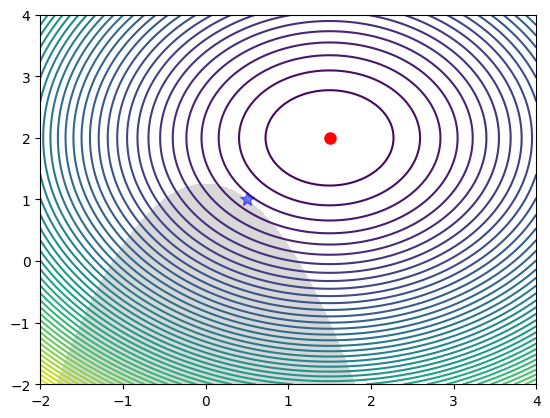

In [48]:
def objective(vars):
    x, y = vars
    f=(x-1.5)**2+(y-2.0)**2
    return f

def constraint(vars):
    x, y = vars
    g=x**2+y-1.25
    return -1*g

# Find the optimal point
init_guess=[0.0,0.0]
result_uncons=minimize(objective,init_guess)
x0,y0=result_uncons.x
cons={'type': 'ineq', 'fun': constraint}
result_cons=minimize(objective,init_guess,constraints=cons)
x1,y1=result_cons.x

# Plot  
x_val=np.linspace(-2,4,100)
y_val=np.linspace(-2,4,100)
X,Y=np.meshgrid(x_val,y_val)
var=(X,Y)
Z=objective(var)
plt.contour(X,Y,Z,levels=50)
G=constraint(var)
plt.contourf(X,Y,G,levels=[0,np.inf],colors='gray',alpha=0.3)
plt.plot(x0,y0,marker='o',color='red',markersize=8, label='Unconstrained')
plt.plot(x1,y1,marker='*',color='blue',alpha=0.5,markersize=10, label='Constrained')
plt.show()

## Part 2: Exact Analytical Solution using KKT Conditions

Now we will find the exact mathematical solution using the Karush-Kuhn-Tucker (KKT) conditions. 

$$ \min_{x, y} f(x, y)  = (x - 1.5)^2 + (y - 2.0)^2  $$

Subject to:
**Inequality Constraint:** $ g(x, y) = x^2 + y - 1.25 \le 0 $

**Task:**
Use Markdown and LaTeX in the space below to solve this problem analytically.
1.  Write out the generalized Lagrangian $\mathcal{L}(x, y, \lambda)$.
2.  Write out the four KKT conditions: Stationarity, Primal Feasibility, Dual Feasibility, and Complementary Slackness.
3.  Solve for the optimal parameters $(x^*, y^*)$ and the dual variable $\lambda^*$. 
4.  Use the `sympy` library to symbolically solve the system of equations derived from the KKT conditions. Instead of assuming the constraint is active, solve the general system using Stationarity and Complementary Slackness. Then, filter the theoretical solutions by checking Primal and Dual feasibility.


### Part 2: Exact Analytical Solution using KKT Conditions
To solve the constrained optimization problem analytically, we first define the generalized Lagrangian function $\mathcal{L}(x, y, \lambda)$:
$$\mathcal{L}(x, y, \lambda) = f(x, y) + \lambda g(x, y) = (x - 1.5)^2 + (y - 2.0)^2 + \lambda(x^2 + y - 1.25)$$
Now, we establish the four **Karush-Kuhn-Tucker (KKT)** conditions for a local minimum:
#### 1. Stationarity
The gradient of the Lagrangian with respect to the primal variables must vanish:
$$\frac{\partial \mathcal{L}}{\partial x} = 2(x - 1.5) + 2\lambda x = 0$$
$$\frac{\partial \mathcal{L}}{\partial y} = 2(y - 2) + \lambda = 0$$
#### 2. Primal Feasibility
The optimal point must satisfy the original constraint:
$$g(x, y) = x^2 + y - 1.25 \le 0$$
#### 3. Dual Feasibility
The Lagrange multiplier corresponding to the inequality constraint must be non-negative:
$$\lambda \ge 0$$
#### 4. Complementary Slackness
The product of the multiplier and the constraint function must equal zero:
$$\lambda (x^2 + y - 1.25) = 0$$
---
### Analytical Solving Procedure
Based on the **Complementary Slackness** condition, we analyze the system by partitioning it into two logical cases:
#### Case A: The constraint is inactive ($\lambda = 0$)
If we assume $\lambda = 0$, the stationarity conditions simplify directly to the unconstrained peak:
$$2(x - 1.5) = 0 \implies x = 1.5$$
$$2(y - 2) = 0 \implies y = 2$$
Now, we must verify this candidate point against **Primal Feasibility**:
$$g(1.5, 2) = (1.5)^2 + 2 - 1.25 = 2.25 + 2 - 1.25 = 3 > 0$$
Since $3 \le 0$ is a **contradiction**, the unconstrained minimum lies outside the feasible region. Thus, the constraint must be active.
#### Case B: The constraint is active ($\lambda > 0$)
If $\lambda > 0$, then from complementary slackness, the constraint function must hold with strict equality:
$$x^2 + y - 1.25 = 0 \implies y = 1.25 - x^2$$
From the second stationarity equation ($\frac{\partial \mathcal{L}}{\partial y} = 0$), we isolate $\lambda$ in terms of $y$ and then substitute $x$:
$$\lambda = 2(2 - y) = 2\left(2 - (1.25 - x^2)\right) = 2(x^2 + 0.75)$$
Substituting this expression for $\lambda$ into the first stationarity equation ($\frac{\partial \mathcal{L}}{\partial x} = 0$):
$$2(x - 1.5) + 2\left[2(x^2 + 0.75)\right]x = 0$$
$$(x - 1.5) + 2x(x^2 + 0.75) = 0$$
$$x - 1.5 + 2x^3 + 1.5x = 0$$
$$2x^3 + 2.5x - 1.5 = 0$$
By solving this cubic equation for its real root, we obtain:
$$x^* = 0.5$$
Now, we back-substitute $x^*$ to find the unique optimal values for $y^*$ and $\lambda^*$:
$$y^* = 1.25 - (0.5)^2 = 1.25 - 0.25 = 1.0$$
$$\lambda^* = 2\left((0.5)^2 + 0.75\right) = 2(0.25 + 0.75) = 2.0$$
#### Conclusion and Verification
* **Primal Feasibility Check:** $g(0.5, 1.0) = 0.5^2 + 1 - 1.25 = 0 \le 0$ (Satisfied, on the boundary)
* **Dual Feasibility Check:** $\lambda^* = 2.0 \ge 0$ (Satisfied)
Therefore, the exact analytical optimal solution matching the KKT conditions is:
$$\boxed{(x^*, y^2) = (0.5, 1.0), \quad \lambda^* = 2.0}$$

In [56]:
x,y,lam=sp.symbols('x y lam',real=True)
f=(x-1.5)**2+(y-2.0)**2
g=(x**2+y-1.25)
L=f+lam*g
dL_dx=sp.diff(L,x)
dL_dy=sp.diff(L,y)
slackness= lam*g
sol=sp.solve([dL_dx,dL_dy,slackness],(x,y,lam),dict=True)
flag=False
x_star=0.0
y_star=0.0
lam_star=0.0
for s in sol:
    x_val=s[x]
    y_val=s[y]
    lam_val=s[lam]
    g_val=g.subs({x:x_val,y:y_val})
    if g_val<=0 and lam_val>=0:
        flag=True
        x_star=x_val
        y_star=y_val
        lam_star=lam_val
        break
if flag:
    print(f'our optimal parameters are {x_star}, {y_star}, {lam_star}')
else:
    print('we do not have optimal solution')

our optimal parameters are 0.500000000000000, 1.00000000000000, 2.00000000000000


## Part 3: The Penalty Method and Optimization Trajectory

In this phase, we will use the **Quadratic Penalty Method** to convert our constrained optimization problem into an unconstrained problem. 

For an inequality constraint $g(x,y) \le 0$, we apply a penalty only when the constraint is violated (i.e., when $g(x,y) > 0$). The penalized objective function $P(x, y; r)$ with penalty parameter $r > 0$ is defined as:

$$ P(x, y; r) = f(x, y) + \frac{r}{2} \max(0, g(x, y))^2 $$

As $r \to \infty$, the solution to the unconstrained minimization of $P(x, y; r)$ approaches the solution of the original constrained problem. 

*Note: In a full Penalty Method algorithm, we would solve this iteratively for a sequence of increasing $r$ values. However, to understand the trajectory and geometry in this step, we will use a **fixed, constant value** for $r$ (e.g., $r = 100$).*

**Tasks:**
1. Define the penalty function.
2. Use `scipy.optimize.minimize` (using an unconstrained solver like 'BFGS') to minimize the penalty function for a constant $r$.
3. Store the trajectory (the $(x,y)$ points visited at each iteration).
4. Plot the optimization trajectory over the contour plot to visualize how the algorithm navigates towards the constrained optimum.


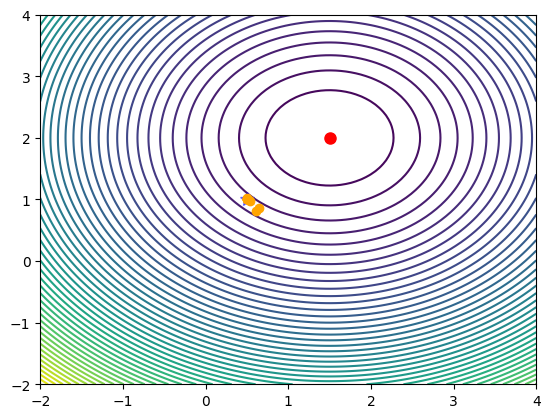

In [62]:
r=100
def penalty_func(vars):
    global r
    g_val=-1*constraint(vars)
    P=objective(vars)+r/2*(np.maximum(0,g_val))**2
    return P
result_penalty=minimize(penalty_func,init_guess,method='BFGS')
trajectory=[]
def storing_path(xk):
    trajectory.append(xk.copy())
res=minimize(penalty_func,init_guess,method='BFGS',callback=storing_path)
traj=np.array(trajectory)
x_traj=traj[:,0]
y_traj=traj[:,1]
x_val=np.linspace(-2,4,100)
y_val=np.linspace(-2,4,100)
X,Y=np.meshgrid(x_val,y_val)
var=(X,Y)
Z=objective(var)
plt.contour(X,Y,Z,levels=50)
plt.plot(x0,y0,marker='o',color='red',markersize=8, label='Unconstrained')
plt.plot(x1,y1,marker='*',color='blue',alpha=0.5,markersize=10, label='Constrained')
plt.plot(x_traj,y_traj,marker='o',color='orange',linestyle='-', linewidth=0.1, label='trajectory')
plt.show()

## Part 4: Convergence Analysis and Ill-conditioning

In the previous phase, we saw that a large penalty parameter $r$ pushes the unconstrained minimum closer to the true constrained minimum. It seems logical to just set $r$ to a massive number (like $10^{10}$) right from the start to get a highly accurate solution. Let's test this hypothesis.

* **Task:**
1. Loop through a logarithmic range of $r$ values (e.g., $r = 10^1, 10^2, \dots, 10^{10}$).
2. For each $r$, minimize the penalty function $P(x, y; r)$.
3. Calculate the $L_2$ error between your numerical solution $x_{num}$ $y_{num}$  and the exact analytical solution $(x^,y^*)=(0.5,1.0)$ (found in Phase 2): 
   $$ E = \sqrt{(x_{\text{num}}-x^*)^2+(y_{\text{num}}-y^*)^2}.$$
4. Plot the error $E$ against $r$ on a log-log scale.

*Question :* 
Looking at your plot, you should notice that the error decreases initially as $r$ grows, but after a certain point, the error sharply increases or the optimization algorithm fails to converge. Why does this happen? Hint: Consider the Hessian matrix of the penalty function as $r \to \infty$.

### Convergence Failure and Ill-conditioning
The fundamental reason for the convergence failure at very large values of $r$ lies in the **ill-conditioning** of the problem.
When the penalty is active ($g(x,y) > 0$), the penalized objective function is:
$$P(x,y;r) = f(x,y) + \frac{r}{2}g(x,y)^2$$
To understand the optimization landscape, we analyze the Hessian matrix of $P$. First, the gradient is:
$$\nabla P = \nabla f + r g \nabla g$$
Taking the second derivative yields the $2 \times 2$ Hessian matrix $H$:
$$H = \nabla^2 P = \nabla^2 f + r \nabla g (\nabla g)^T + r g \nabla^2 g$$
As the algorithm approaches the boundary of the feasible region, $g(x,y) \approx 0$. Therefore, the third term diminishes, and the Hessian can be approximated as:
$$H \approx \nabla^2 f + r \nabla g (\nabla g)^T$$
The term $r \nabla g (\nabla g)^T$ is a rank-1 matrix that dominates the behavior of $H$ as $r$ grows. Because the Hessian is a $2 \times 2$ matrix, it possesses two eigenvalues ($\lambda_1, \lambda_2$). Based on this approximation:
* The **maximum eigenvalue** ($\lambda_{\max}$) is associated with the eigenvector pointing in the direction of $\nabla g$ (perpendicular to the constraint boundary). This eigenvalue grows linearly with $r$, meaning $\lambda_{\max} \propto r$.
* The **minimum eigenvalue** ($\lambda_{\min}$) is associated with the direction tangent to the boundary. It is primarily determined by $\nabla^2 f$ and remains relatively constant ($O(1)$), regardless of how large $r$ gets.
The **condition number** ($\kappa$) of the Hessian matrix is defined as the ratio of its maximum to minimum eigenvalue:
$$\kappa(H) = \frac{\lambda_{\max}}{\lambda_{\min}} \propto r$$
Consequently, as $r \to \infty$, the condition number approaches infinity ($\kappa \to \infty$), making the Hessian matrix highly ill-conditioned. In this steep, narrow, valley-like geometry, even a tiny numerical noise or floating-point rounding error in calculating the step size causes the optimization algorithm (like BFGS) to oscillate with a very large magnitude, ultimately leading to a failure to converge.

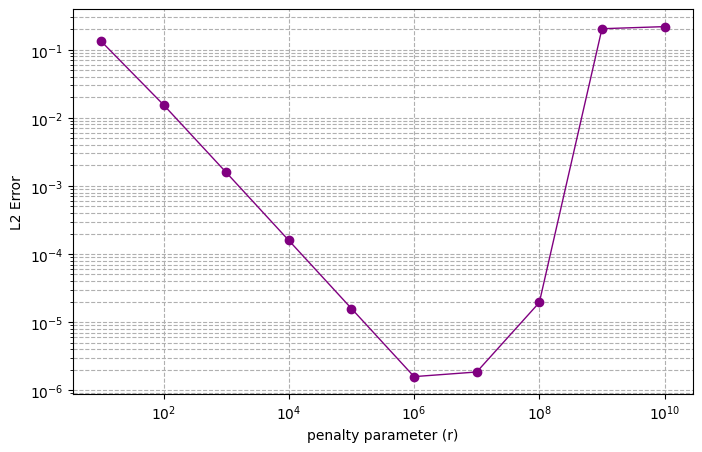

In [64]:
r_val=np.logspace(1,10,num=10)
error=[]
x_star=float(x_star)
y_star=float(y_star)
for r_cur in r_val:
    global r
    r=r_cur
    res=minimize(penalty_func,init_guess,method='BFGS')
    x_num,y_num=res.x
    er=np.sqrt((x_num-x_star)**2+(y_num-y_star)**2)
    error.append(er)
plt.figure(figsize=(8,5))
plt.loglog(r_val,error,marker='o',color='purple',linewidth=1)
plt.xlabel('penalty parameter (r)')
plt.ylabel('L2 Error')
plt.grid(True,which='both',ls='--')
plt.show()

## Part 5: The Augmented Lagrangian Method (ALM)

In the previous section, we saw the fundamental flaw of the Quadratic Penalty method: to get an accurate solution, we must push the penalty parameter $r$ to infinity, but doing so causes severe *ill-conditioning. The Hessian becomes extremely skewed, and numerical solvers like BFGS fail.

The Augmented Lagrangian Method (ALM), also known as the Method of Multipliers, elegantly solves this. By explicitly incorporating an estimate of the Lagrange multiplier $\lambda$, ALM achieves accurate convergence without needing $r \to \infty$. We can keep $r$ at a moderate, computationally safe value.

For an inequality constraint

$$
g(x,y) \le 0,
$$

the Augmented Lagrangian function is defined as:

$$
\mathcal{L}_A(x,y,\lambda,r)
=
f(x,y)
+
\frac{1}{2r}
\left(
\max(0, \lambda + r g(x,y))^2 - \lambda^2
\right).
$$

The ALM Algorithm:

1. Fix a moderate penalty parameter $r > 0$, for example $r=10$.
2. Initialize $\lambda_0 = 0$ and a starting guess $(x_0,y_0)$.
3. Inner Loop: Minimize $\mathcal{L}_A(x,y,\lambda_k,r)$ with respect to $(x,y)$ to find $(x_k^,y_k^*)$.
4. *Multiplier Update: Update the Lagrange multiplier using
   $$
   \lambda_{k+1}
   =
   \max(0, \lambda_k + r g(x_k^,y_k^*)).
   $$
5. Repeat steps 3 and 4 until convergence.

* **Tasks:**

1. Define the augmented Lagrangian function $\mathcal{L}_A(x,y,\lambda,r)$.

2. Implement the ALM loop with $r=10$, $\lambda_0=0$, and $(x_0,y_0)=(4,4)$ using `scipy.optimize.minimize`.

3. At each iteration, update $\lambda_{k+1}=\max(0,\lambda_k+r g(x_k^,y_k^*))$ and store $x_k$, $y_k$, $f(x_k,y_k)$, $g(x_k,y_k)$, and $\lambda_k$.

4. Print an iteration table for $k$, $x_k$, $y_k$, $f(x_k,y_k)$, $g(x_k,y_k)$, and $\lambda_k$.

5. Create two plots: one showing the ALM trajectory with the feasible region, constraint boundary, starting point, final point, exact KKT solution, and unconstrained minimizer; and another showing the error $\sqrt{(x_k-0.5)^2+(y_k-1.0)^2}$ versus iteration number.

6. Compare the final ALM solution with $(x^*,y^*)=(0.5,1.0)$ and $\lambda^*=2$ by computing $\sqrt{(x_{\text{ALM}}-0.5)^2+(y_{\text{ALM}}-1.0)^2}$, $|\lambda_{\text{ALM}}-\lambda^*|$, and $|g(x_{\text{ALM}},y_{\text{ALM}})|$.

7. Briefly compare ALM with the Quadratic Penalty method.

 k     x_k     y_k   f_val    g_val      lam
 0 0.54606 1.12652 1.67298  0.17470 0.000000
 1 0.50554 1.01644 1.95633  0.02202 1.746964
 2 0.50072 1.00214 1.99429  0.00286 1.967115
 3 0.50009 1.00028 1.99925  0.00037 1.995712
 4 0.50001 1.00004 1.99990  0.00005 1.999441
 5 0.50000 1.00000 1.99999  0.00001 1.999927
 6 0.50000 1.00000 2.00000  0.00000 1.999990
 7 0.50000 1.00000 2.00000 -0.00000 2.000001
 8 0.50000 1.00000 2.00000 -0.00000 2.000000
 9 0.50000 1.00000 2.00000 -0.00000 1.999999


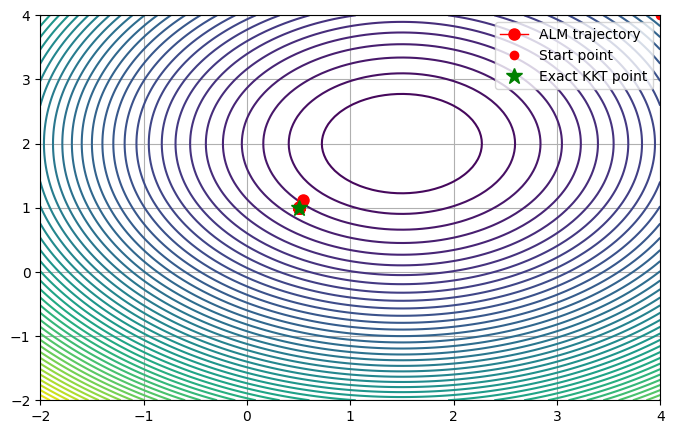

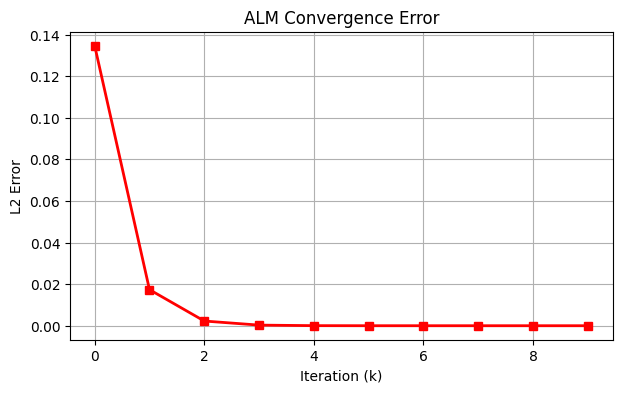

Final Solution Error: 1.84e-06
Multiplier Error (|lambda_ALM - lambda*|): 1.69e-06
Constraint Violation (|g(x,y)|): 8.91e-08


In [71]:
def augmented_lag(vers,lam,r):
    g_val=-1*constraint(vers)
    penalty=(np.maximum(0,lam+r*g_val)**2-lam**2)
    L_a=objective(vers)+penalty/(2*r)
    return L_a
lam=0.0
r=10
cur_guess=np.array([4.0, 4.0])
alm_hist=[]
it_num=10
for k in range(it_num):
    res=minimize(augmented_lag,cur_guess,args=(lam,r),method='BFGS')
    xk,yk=res.x
    g_val=-1*constraint(res.x)
    f_val=objective(res.x)
    lamk=np.maximum(0,lam+r*g_val)

    alm_hist.append({'k': k,'x_k':xk,'y_k':yk,'f_val':f_val,'g_val':g_val,'lam':lam})
    cur_guess=res.x
    lam=lamk
df=pd.DataFrame(alm_hist)
print(df.to_string(index=False,formatters={'x_k': '{:.5f}'.format,
    'y_k': '{:.5f}'.format,
    'f_val': '{:.5f}'.format,
    'g_val': '{:.5f}'.format,
    'lambda_k': '{:.5f}'.format}))
x_traj_alm=df['x_k'].values
y_traj_alm=df['y_k'].values
plt.figure(figsize=(8,5))
plt.contour(X,Y,Z,levels=50)
plt.plot(x_traj_alm,y_traj_alm,marker='o',color='red',markersize=8, linestyle='-', label='ALM trajectory',linewidth=1)
plt.plot(4, 4, 'ro', label='Start point')
plt.plot(0.5, 1.0, 'g*', markersize=12, label='Exact KKT point')
plt.grid(True)
plt.legend()
plt.show()
errors_alm=np.sqrt((df['x_k']-0.5)**2+(df['y_k']-1.0)**2)
plt.figure(figsize=(7, 4))
plt.plot(df['k'],errors_alm,marker='s',color='red',linewidth=2)
plt.xlabel('Iteration (k)')
plt.ylabel('L2 Error')
plt.title('ALM Convergence Error')
plt.grid(True)
plt.show()
x_f=df['x_k'].iloc[-1]
y_f=df['y_k'].iloc[-1]
g_f=df['g_val'].iloc[-1]
dist_error=np.sqrt((x_f-0.5)**2+(y_f-1.0)**2)
lam_error=abs(lam-2.0)
g_error=abs(g_f)
print(f"Final Solution Error: {dist_error:.2e}")
print(f"Multiplier Error (|lambda_ALM - lambda*|): {lam_error:.2e}")
print(f"Constraint Violation (|g(x,y)|): {g_error:.2e}")

---

# Problem 5

## Matrix Transformation

 In many applications of engineering and computer science, matrices are not just collections of numbers—they are tools for manipulating geometric objects. A matrix can change the position, direction, or shape of a vector. For example, a matrix can rotate a shape, scale it up or down, or distort it in space.

 This ability, known as a **“linear transformation”** is a fundamental concept behind computer graphics, machine vision, image processing, and simulations. In this assignment, you will explore how matrices affect vectors and analyze the changes they create in geometric space. In other words, instead of focusing only on calculations, you will study matrices as instruments for modeling and transforming space.

## Base Shape

In computer graphics, 2D shapes are usually described as a list of ordered vertices (points). When we connect these points in order, we get a complete shape. In the language of linear algebra, each point (x,y) can be represented as a column vector:
$$
\begin{bmatrix}  x  \\  y  \end{bmatrix} 
$$

This perspective allows us to use matrices to transform shapes—rotating, scaling, or shearing them—by simply multiplying the vectors by transformation matrices.

Task: Below, you will find some starter code that:
Defines a simple 2D shape as a list of vertices.
Provides a helper function to visualize (plot) the shape.
Run the code to familiarize yourself with how the shape is represented and plotted. This will serve as the foundation for the transformations in the upcoming exercises.

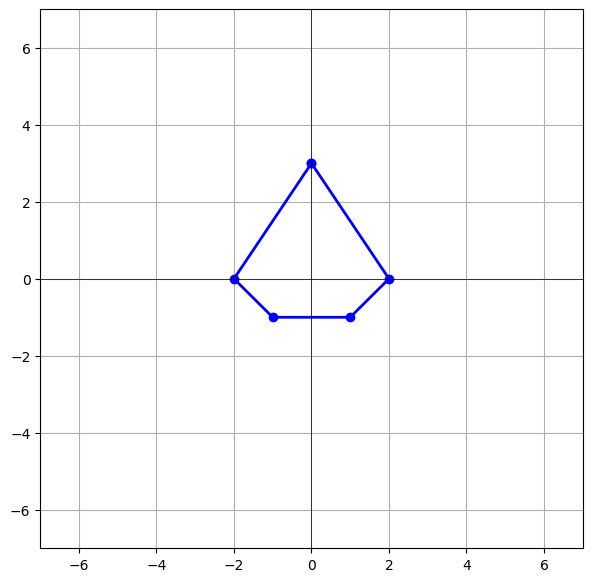

In [4]:
base_shape = np.array([
    [0,-2,-1,  1,  2, 0], # x-coordinates
    [3,0,-1, -1, 0, 3 ]  # y-coordinates
])


def plot_shape(shape1, title="Shape", color='blue'):
    """
    Plots a 2D shape defined by a 2xN (or 3xN) matrix.
    - matrix: 2xN (or 3xN) NumPy array, where each column is a vertex.
    - title: plot title
    - color: line color
    """
    # Use only first 2 rows in case of homogeneous coordinates (3xN)
    x_c1 = shape1[0, :]
    y_c1 = shape1[1, :]
  
    plt.figure(figsize=(7, 7))
    plt.plot(x_c1, y_c1, '-o', color=color, linewidth=2)  # Connect points
  
    plt.axhline(0, color='black', linewidth=0.5)  # x-axis
    plt.axvline(0, color='black', linewidth=0.5)  # y-axis
    plt.grid(True)
    plt.xlim(-7, 7)
    plt.ylim(-7, 7)
    plt.show()

# Visualize the original shape
plot_shape(base_shape, "Base Shape")


# 1-1: Linear Transformations 
A linear transformation takes a vector as input and maps it to a new vector such that the origin (0,0) stays fixed. In matrix terms, this is simply:
$$
V_{new}=M \cdot V_{old}
$$
Here, M is a transformation matrix that defines how the vector is changed. By multiplying a matrix with all the vertices of a shape, we can manipulate the entire shape in space.
## Part 1: Scaling
Scaling stretches or shrinks the space along the x- and y-axes. The scaling matrix is:
$$ S = \begin{bmatrix} s_x & 0 \\ 0 & s_y \end{bmatrix} $$
Where:
$s_{x}$	scales along the x-axis and
$s_{y}$	scales along the y-axis


### Task:
1. Write a function `scaling_matrix(sx, sy)` that returns the corresponding 2×2 scaling matrix.
2. Apply it to your shape to scale¨ $$(x,y)=(2,0.5)$$
3. Visualize the scaled shape using plot_shape().

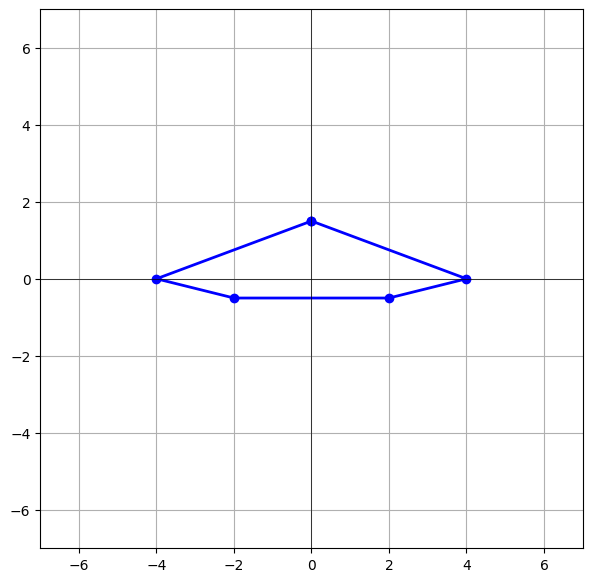

In [5]:
def scaling_matrix(sx, sy):
    S=np.array([[sx, 0],[0,sy]])
    return S
S1=scaling_matrix(2,0.5)
scaled_shape= S1 @ base_shape
plot_shape(scaled_shape,"New shape")

## Part 2: Rotation
A rotation transformation changes the direction of a vector while preserving its distance from the origin. To rotate a vector counter-clockwise by an angle θ, we use the following rotation matrix:
$$ R = \begin{bmatrix} \cos\theta & -\sin\theta \\ \sin\theta & \cos\theta \end{bmatrix} $$


### Task: 
- Write a function `rotation_matrix(Θ)`.
- Rotate the original shape **70 degrees counter-clockwise**.
- Plot the transformed shape and compare it with the original.


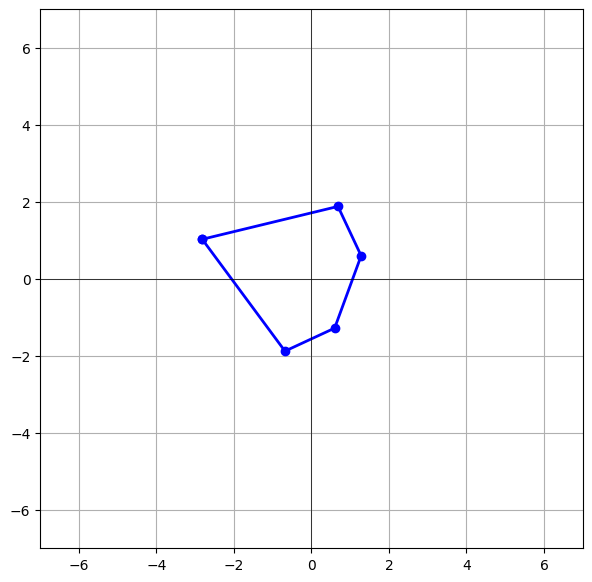

In [6]:
def rotation_matrix(degree):
    S=np.array([[np.cos(degree),-np.sin(degree)],[np.sin(degree),np.cos(degree)]])
    return S
rotated_shape=rotation_matrix(np.pi/18*7)@base_shape
plot_shape(rotated_shape,"Rotated shape")

# 1-2:  Translation 
Suppose we want to move the shape to a new position, for example (3,2). A standard 2×2 matrix cannot perform translation because linear transformations must map the zero vector (0,0) to itself—the origin cannot move.
To overcome this limitation, we use homogeneous coordinates. The idea is simple: we add a third “dummy” dimension equal to 1 to every vector:
$$
 (x, y) \rightarrow (x, y, 1) 
$$

This extra dimension allows us to combine translation with other linear transformations into a single 3×3 matrix.
## Part 1: Homogenization


### Task:
1. Write a function `to_homogeneous(matrix)` that converts a 2×N shape matrix into 3×N by stacking a row of 1s at the bottom.
2. Apply it to the original shape and check the result.

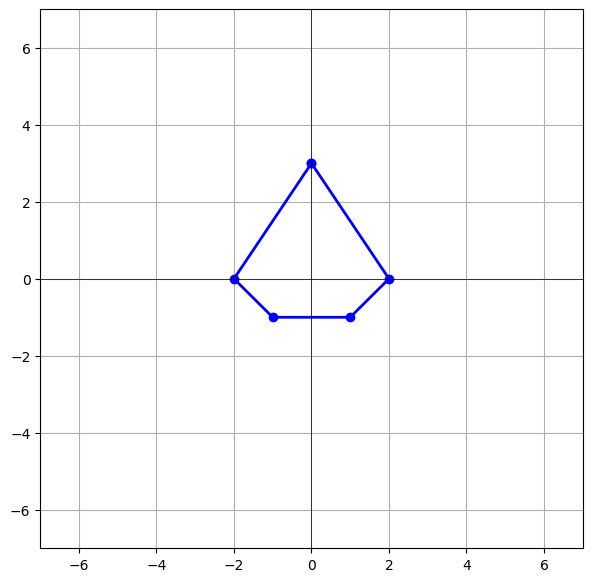

In [7]:
def to_homogeneous(matrix):
    f_row=np.ones((matrix.shape[1]))
    m=np.vstack((matrix,f_row))
    return m
homogeneous_shape=to_homogeneous(base_shape)
plot_shape(homogeneous_shape,"Translated shape")

## Part 2: Translation 
Once the shape has been converted to homogeneous coordinates, we can use a 3×3 translation matrix to move it anywhere in the plane.
The translation matrix is:
$$ T = \begin{bmatrix} 1 & 0 & t_x \\ 0 & 1 & t_y \\ 0 & 0 & 1 \end{bmatrix} $$

### Task:
1. Write a `translation_matrix(tx, ty)` func.
2. Translate the shape by $t_{x}$=3  and  $t_{y}$=1.
3. Plot the translated shape.

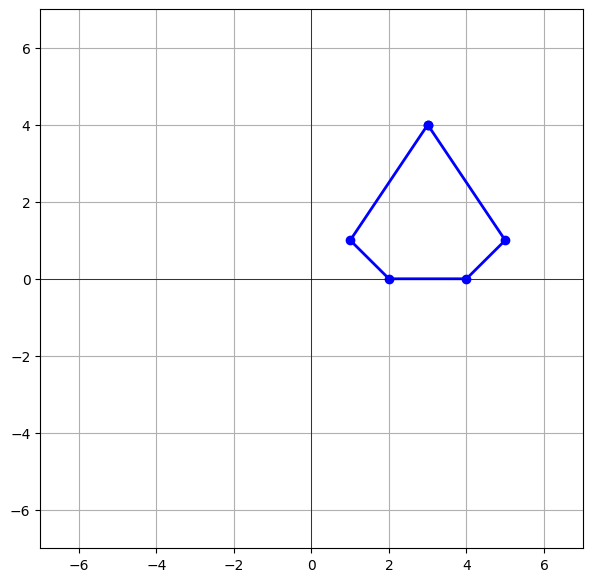

In [8]:
def translation_matrix(tx, ty):
    T=np.array([[1,0,tx],[0,1,ty],[0,0,1]])
    return T
homogeneous_shape=to_homogeneous(base_shape)
translation_shape=translation_matrix(3,1)@homogeneous_shape
plot_shape(translation_shape,"Translated shape")

## 1-3: Matrix Composition
In a 2D game, objects are often transformed using several operations at once. For example, a shooter may need to move to a new position and then rotate to aim at a target.
However, matrix multiplication is not commutative:
$$
(A \cdot B \neq B \cdot A)
$$
This means that changing the order of transformations can completely change the final result.
Imagine your shooter is located at position (3,2). You want the shooter to rotate around its own center, not around the world origin (0,0). If you apply a rotation matrix directly after moving the shooter, the shooter will rotate around the origin and may swing away from its intended position.


### Local Rotation Idea
To rotate an object around its own center, we use three steps:
1. Move the object back to the origin.
2. Rotate the object.
3. Move the object back to its position.

$$
 R_{local} = T \cdot R \cdot T^{-1} 
$$
**Important Note**
- For this exercise, you do not need to compute a matrix inverse.
Since T is a pure translation matrix, its inverse can be obtained by simply negating the translation values:
$$ T = \begin{bmatrix} 1 & 0 & t_x \\ 0 & 1 & t_y \\ 0 & 0 & 1 \end{bmatrix} $$
$$ T^{-1} = \begin{bmatrix} 1 & 0 & -t_x \\ 0 & 1 & -t_y \\ 0 & 0 & 1 \end{bmatrix} $$

## Task:
0. Write a function `local_rotation(matrix, Θ, tx, ty)` that applies local rotation to a shape.
1. Convert the original shape to **homogeneous coordinates** using `to_homogeneous(matrix)`.

2. Create a 3×3 rotation matrix (R) (**Θ degrees counter-clockwise**).

3. Create a translation matrix that moves the shape to (tx,ty) ($T_{1}$).

4. Create the inverse translation matrix $T_{2}$ by negating the translation values.. 

5. Construct the composite local rotation matrix:
$$ 
R_{local} = T_{1} \cdot R \cdot T_{2}
$$
6. Apply it on the **homogeneous of matrix**.(return the resault)


## Experiment:

7. you have been given a T_shape matrix that is a 2xN translated of matrix base shape to (3,2).

8. rotate T_shape **(50 degrees)** and plot the results. **(M1)**

9. Apply your function `local_rotation(matrix,50,1,3)` on the **base shape** and plot the results. **(M2)**

10. Compare the plots from **(M1)** and **(M2)**. 




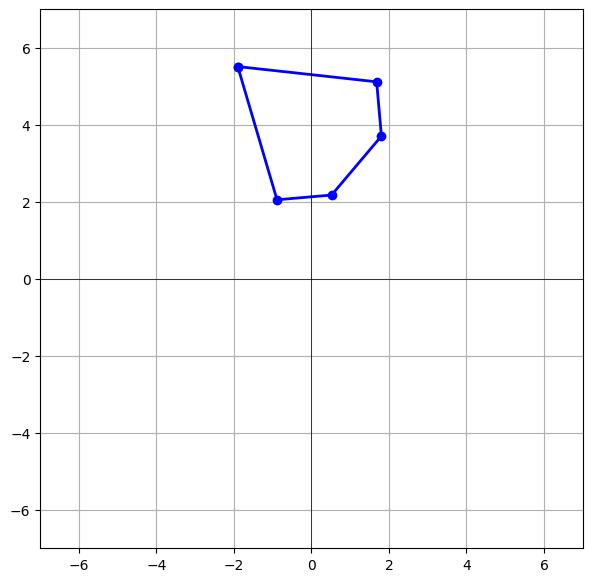

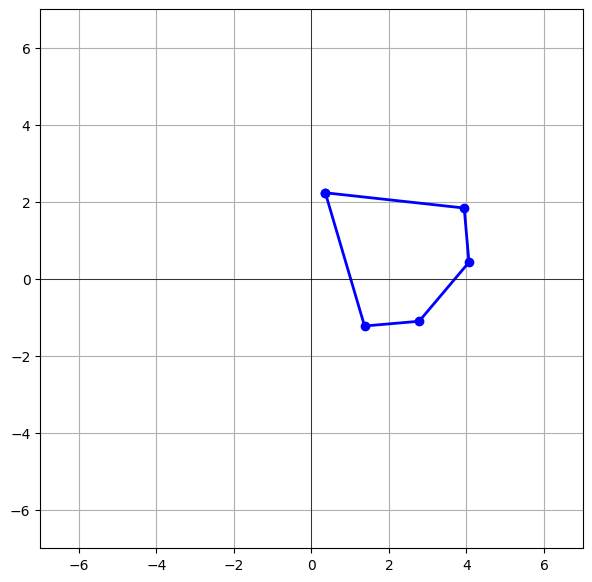

In [11]:
def local_rotation(matrix,degree,tx,ty):
    homo=to_homogeneous(matrix)
    R_2=rotation_matrix(degree)
    R=np.eye(3)
    R[:2,:2]=R_2
    T1=translation_matrix(tx,ty)
    T2=translation_matrix(-tx,-ty)
    R_local=(T1@R)@T2
    result=R_local@homo
    return result[:2, :]
T_shape=np.array([
    [3,1,2,  4,  5, 3], # x-coordinates
    [5,2,1, 1, 2, 5 ]  # y-coordinates
])
M1=rotation_matrix(np.pi/18*5)@T_shape
M2=local_rotation(base_shape,np.pi/18*5,1,3)
plot_shape(M1,"rotated shape")
plot_shape(M2,"local rotated shape")

# MINI GAME : Shooter vs Moving Target — Game Simulation

In this mini-game, you will simulate a 2D shooter aiming at a moving target. The goal is to combine translation, local rotation (TRT⁻¹), and a motion error to hit the target within a limited number of shots.

---

## Game Setup

### 1. Target Ball

* Has 5 health points (HP).
* Appears at a new random position each frame.
* Represented as a 2×1 matrix:

$$ Target = \begin{bmatrix} t_{x}\\t_{y} \end{bmatrix} $$
### 2. Shooter

* Defined as a `base_shape` matrix.
* Moves along the x-axis (0.25 units each frame).
* Can rotate locally to aim at the target using a local rotation function.

### 3. Shooter Motion & Error

* Because the shooter is moving, the aiming angle will include a 2.5% random adjustment (motion error) x speed **(it depends on your moving speed)**.
* Adjust the angle using:

$$
Θ_{shooting} = Θ_{aiming} \cdot f 
$$
-for example for speed=2 we have 5% aiming error:
$$
f \in [0.95,1.05]
$$

---

## Shooter Transformations

To rotate the shooter around its own center rather than the world origin:

$$
R_{local} = T \cdot R \cdot T^{-1}
$$

* Use `local_rotation(matrix, Θ, tx, ty)`

---

## Game Rules

* Maximum 10 shots.
* Target HP = 5.
* Each successful hit reduces HP by 1.

In each frame:

1. The shooter moves along the x-axis.
2. The target appears at a random position.
3. Compute the aiming angle toward the target.
4. Apply the ±5% motion error.
5. Rotate the shooter locally toward the adjusted angle.
6. Check if the shooter hits the target.
7. Reduce HP if the shot is successful.

The game ends when:

* Target HP = 0 → You win!
* All 10 shots are used → Game over!

---

## Task

Write a function `shooter_shape_angle(shooter_shape, shooter_pos, target_pos)` which returns:

1. The shooting angle after applying the motion error.
2. The shape of the moving and rotated shooter **(`rotated_shooter`)** using `local_rotation(matrix, Θ, tx, ty)`.

Inside your function:

1. Compute the aiming angle toward the target `theta`.
2. Apply the motion error.
3. Rotate the shooter using `local_rotation(...)`.
4. Return both the final angle and `rotated_shooter`.

Finally:

1. Apply the game plot and observe your simulation.
2. Play with different shooter speeds and compare the winning possibilities.


In [24]:
def shooter_shape_angle(shooter_shape,shooter_pos, target_pos,speed):
    dy=(-shooter_pos[1]+target_pos[1]).item()
    dx=(-shooter_pos[0]+target_pos[0]).item()
    theta=np.arctan2(dy,dx)
    # do not change this part
    #--------------------------------
    percent = 0.025
    s=speed*percent 
    error_factor = np.random.uniform(1-s, 1+s)
    theta = theta * error_factor
    print(speed)
    #--------------------------------
    tx=shooter_pos[0]
    ty=shooter_pos[1]
    rotated_shooter=local_rotation(shooter_shape,theta,tx,ty)
    theta_degree=np.degrees(theta)
    return rotated_shooter,theta_degree

2


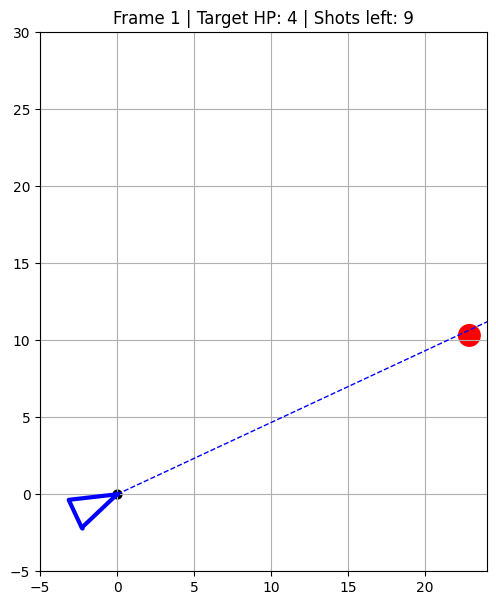

2


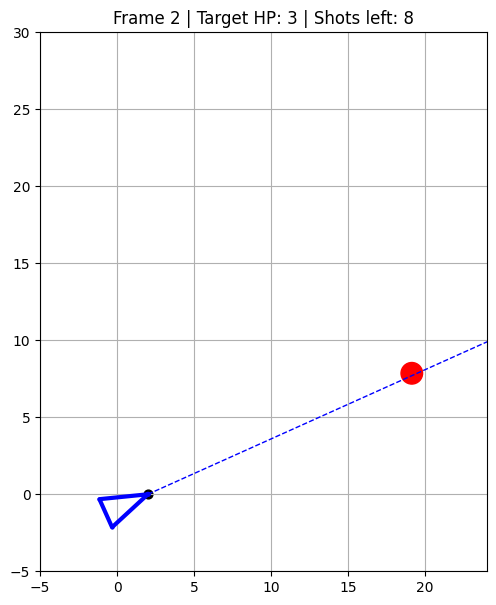

2


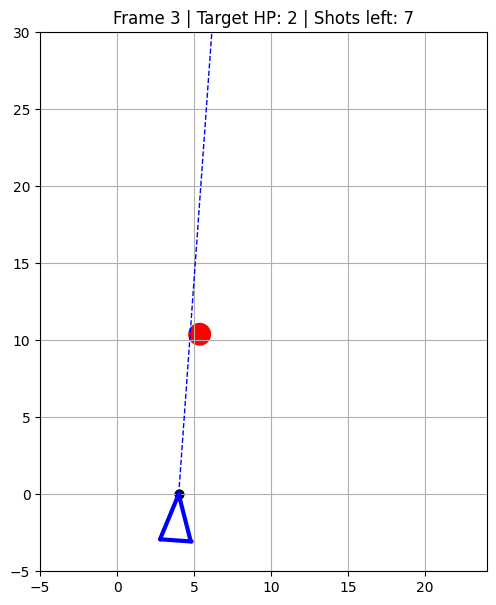

2


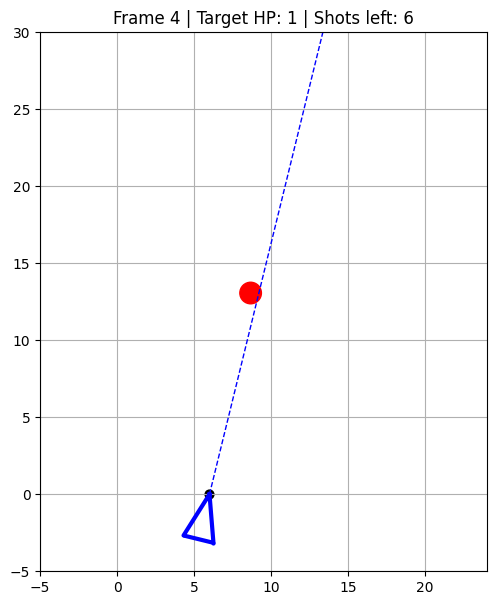

2


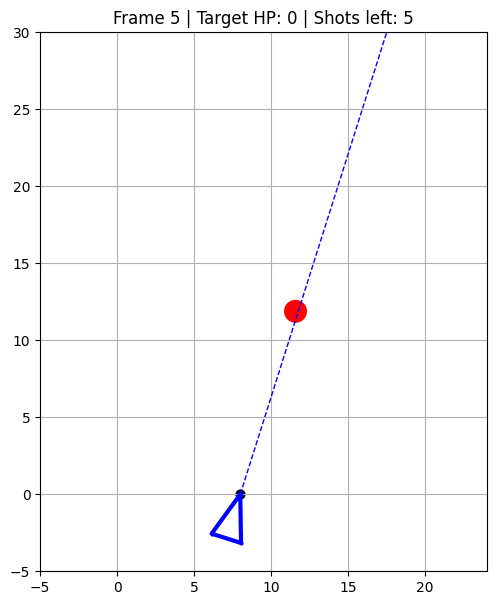

You win! Target destroyed in 5 shots.


In [26]:
#Game Plate

#you can change the speed of your movement here:
speed=2
#--------------------------------
# do not change anything here:
# -------------------------------
# Base shooter shape
# -------------------------------
base_shooter = np.array([
    [0, -3, -3, 0,],      # x-coordinates
    [0, -1, 1, 0]    # y-coordinates
])

shot_length = 40


# -------------------------------
# Plot function
# -------------------------------
def plot_frame(shooter, target, hp, shots_left, frame, theta, shooter_pos):
    fig, ax = plt.subplots(figsize=(7, 7))

    ax.plot(
        shooter[0, :],
        shooter[1, :],
        '-o',
        color='blue',
        linewidth=3,
        markersize=2
    )

    angle_rad = np.radians(theta)
    x0, y0 = shooter_pos

    ax.plot(
        [x0, x0 + shot_length * np.cos(angle_rad)],
        [y0, y0 + shot_length * np.sin(angle_rad)],
        color='blue',
        linewidth=1,
        linestyle='--'
        
    )

    ax.add_patch(
        plt.Circle(
            (target[0, 0], target[1, 0]),
            0.7,
            color='red'
        )
    )

    ax.scatter(x0, y0, color='black', s=40)

    ax.set_title(f"Frame {frame} | Target HP: {hp} | Shots left: {shots_left}")
    ax.set_xlim(-5, speed * 12)
    ax.set_ylim(-5, 30)
    ax.set_aspect('equal')
    ax.grid(True)
    plt.show()


# -------------------------------
# Hit check function
# -------------------------------
def check_hit(shooter_pos, target_pos, angle_deg, target_radius=0.7):
    xs, ys = shooter_pos
    xt, yt = target_pos[0, 0], target_pos[1, 0]

    angle_rad = np.radians(angle_deg)

    direction = np.array([
        np.cos(angle_rad),
        np.sin(angle_rad)
    ])

    shooter_point = np.array([xs, ys])
    target_point = np.array([xt, yt])

    vector_to_target = target_point - shooter_point
    projection_length = np.dot(vector_to_target, direction)

    if projection_length < 0:
        return False

    closest_point = shooter_point + projection_length * direction
    distance_to_line = np.linalg.norm(target_point - closest_point)

    return distance_to_line <= target_radius


# -------------------------------
# Game loop
# -------------------------------
target_hp = 5
max_shots = 10

shooter_x = 0
shooter_y = 0
dx = speed

for frame in range(1, max_shots + 1):

    shooter_pos = [shooter_x, shooter_y]

    target_pos = np.array([
        [np.random.uniform(5, 25)],
        [np.random.uniform(5, 25)]
    ])
    
    # فقط تابع دانشجو صدا زده می‌شود
    rotated_shooter, theta = shooter_shape_angle(
        base_shooter,
        shooter_pos,
        target_pos,
        speed
    )
   
    if check_hit(shooter_pos, target_pos, theta):
        target_hp -= 1

    shots_left = max_shots - frame

    plot_frame(
        rotated_shooter,
        target_pos,
        target_hp,
        shots_left,
        frame,
        theta,
        shooter_pos
    )

    shooter_x = shooter_x+ dx
    base_shooter[0, :]= base_shooter[0, :] + dx

    if target_hp <= 0:
        print(f"You win! Target destroyed in {frame} shots.")
        break

if target_hp > 0:
    print("Game Over! Target survived.")